# Gaussian mixture (GMM) segmentation
Loads the features built by `build_features.py` (`output/obs_features.parquet`).

Unlike k-means, a GMM allows clusters of different shapes and sizes and gives each observation a
**probability** of belonging to each cluster.

1. Choose the number of components from BIC (lower = better) and the covariance type.
2. Check how confident the assignments are.
3. Label clusters from the heatmap; validate with bad rates and stability over months.

## Settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

pd.set_option('display.max_columns', None)

FEATURES_FILE = 'output/obs_features.parquet'   # created by build_features.py
RANDOM_STATE = 42

CLUSTER_FEATURES = [
    'avg_period_income',          # income level
    'income_cv',                  # income volatility
    'recent_vs_avg_income',       # income direction (recent vs usual)
    'pay_gap_cv',                 # pay day regularity
    'avg_spend_ratio',            # spend vs pay
    'avg_spend_per_day',          # spending level
    'avg_frac_to_half',           # how quickly pay is spent
    'avg_first3_share',           # spending straight after pay day
    'bal7_ratio_avg',             # share of pay left a week after pay day (usual cycles)
    'bal7_ratio_change',          # latest cycle vs usual (<0 = less left than usual)
    'committed_share_after_pay',  # share of first-3-day outflows that are debit orders
]
LOG_FEATURES = ['avg_period_income', 'avg_spend_per_day']

# 0/1 flags from build_features.py saying WHY a feature was missing (the feature itself was filled)
FLAG_FEATURES = ['no_income_detected', 'few_pay_events', 'no_complete_cycle', 'no_bal7_history']
FLAG_WEIGHT = 1.0    # 0 = ignore flags, lower (e.g. 0.5) if clusters just split on the flags

from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

K = 4                        # set after looking at the BIC plot below
COVARIANCE_TYPE = 'full'     # 'full', 'diag', 'tied' or 'spherical'

## Load features

In [2]:
obs = pd.read_parquet(FEATURES_FILE)
base = obs[obs['exclude_flag'] == 0].copy()

missing = base[CLUSTER_FEATURES].isna().sum().sum()
assert missing == 0, f'{missing} missing values - rerun build_features.py with FILL_MISSING = True'
display(base[FLAG_FEATURES].mean().round(3).to_frame('share_flagged'))

data = base[['obs_id'] + CLUSTER_FEATURES + FLAG_FEATURES].copy()
print(f'Clustering all {len(data):,} observations')

,share_flagged
no_income_detected,0.041
few_pay_events,0.381
no_complete_cycle,0.151
no_bal7_history,0.205


Clustering all 10,499 observations


## Prepare: log, winsorize, scale

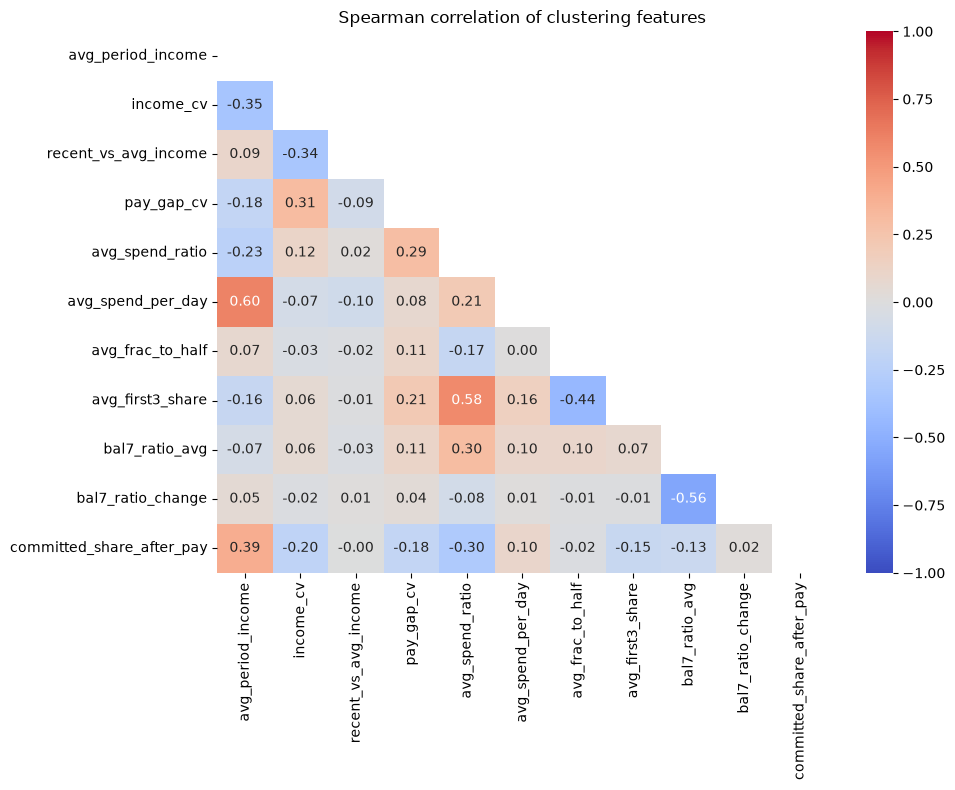

In [3]:
X = data[CLUSTER_FEATURES].copy()
for col in LOG_FEATURES:
    X[col] = np.log1p(X[col].clip(lower=0))
X = X.clip(lower=X.quantile(0.01), upper=X.quantile(0.99), axis=1)   # winsorize 1% / 99%

# Scale the features; flags stay 0/1 (times FLAG_WEIGHT) so scaling doesn't blow them up
X_scaled_df = pd.DataFrame(StandardScaler().fit_transform(X), columns=CLUSTER_FEATURES, index=X.index)
flags = data[FLAG_FEATURES]
X_scaled_df = X_scaled_df.join(flags * FLAG_WEIGHT)
X_scaled = X_scaled_df.to_numpy()

# Spearman correlation of the clustering features (|r| > 0.7 = consider dropping one)
corr = X.corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Spearman correlation of clustering features')
plt.tight_layout()
plt.show()

SIL_SAMPLE = min(10_000, len(X_scaled))

## Choose the number of components and covariance type
- **BIC / AIC**: lower is better. BIC penalises extra parameters more, so it is the usual choice.
- `full` = each cluster has its own shape and orientation; `diag` = axis-aligned shapes;
  `tied` = all clusters share one shape; `spherical` = round, closest to k-means.

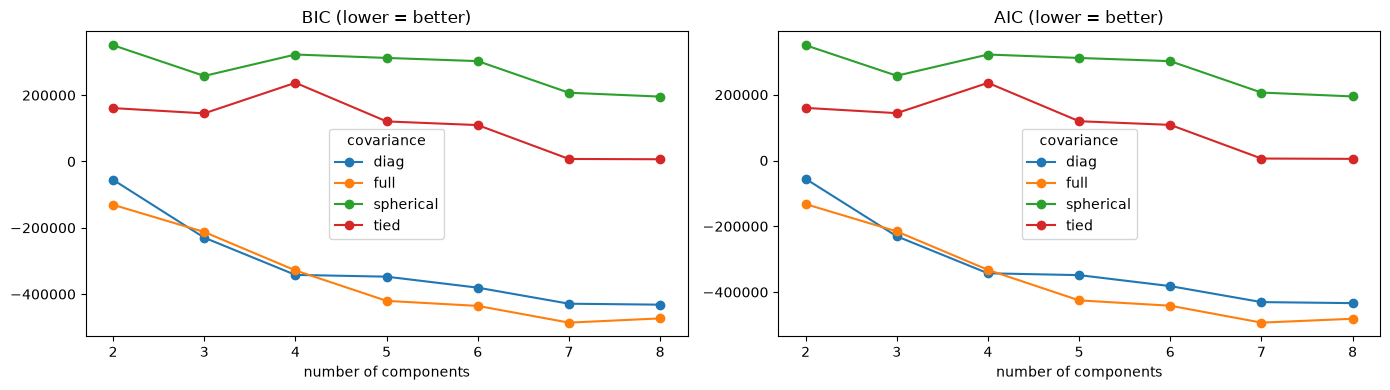

covariance,diag,full,spherical,tied
k,,,,
2,-55183.0,-130576.0,350797.0,161050.0
3,-229680.0,-212630.0,258085.0,145199.0
4,-342023.0,-328570.0,322700.0,237431.0
5,-347386.0,-420344.0,312407.0,120883.0
6,-380575.0,-435596.0,302812.0,109876.0
7,-428957.0,-486028.0,207431.0,7646.0
8,-431841.0,-473285.0,195774.0,6780.0


Lowest BIC: full with k = 7 (BIC often keeps falling; prefer the k where it flattens and the clusters are interpretable)


In [4]:
ks = range(2, 9)
rows = []
for cov in ['full', 'diag', 'tied', 'spherical']:
    for k in ks:
        g = GaussianMixture(n_components=k, covariance_type=cov, n_init=3,
                            random_state=RANDOM_STATE).fit(X_scaled)
        rows.append({'covariance': cov, 'k': k, 'bic': g.bic(X_scaled), 'aic': g.aic(X_scaled)})
ic = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for cov, d in ic.groupby('covariance'):
    axes[0].plot(d['k'], d['bic'], marker='o', label=cov)
    axes[1].plot(d['k'], d['aic'], marker='o', label=cov)
axes[0].set(title='BIC (lower = better)', xlabel='number of components')
axes[1].set(title='AIC (lower = better)', xlabel='number of components')
axes[0].legend(title='covariance'); axes[1].legend(title='covariance')
plt.tight_layout()
plt.show()

display(ic.pivot(index='k', columns='covariance', values='bic').round(0))
best = ic.loc[ic['bic'].idxmin()]
print(f"Lowest BIC: {best['covariance']} with k = {int(best['k'])} "
      '(BIC often keeps falling; prefer the k where it flattens and the clusters are interpretable)')

## Silhouette and Davies-Bouldin for the chosen covariance type
(For comparison with k-means; these favour round clusters, so they can understate a GMM.)

In [5]:
rows = []
for k in ks:
    lab = GaussianMixture(n_components=k, covariance_type=COVARIANCE_TYPE, n_init=3,
                          random_state=RANDOM_STATE).fit_predict(X_scaled)
    if len(set(lab)) < 2:
        continue
    rows.append({'k': k,
                 'silhouette': silhouette_score(X_scaled, lab, sample_size=SIL_SAMPLE, random_state=RANDOM_STATE),
                 'davies_bouldin': davies_bouldin_score(X_scaled, lab)})
display(pd.DataFrame(rows).set_index('k').round(3))

,silhouette,davies_bouldin
k,,
2,0.189,1.855
3,0.184,2.876
4,0.122,3.009
5,0.128,2.271
6,0.129,2.207
7,0.105,2.742
8,0.117,2.309


## Fit final model

In [6]:
gmm = GaussianMixture(n_components=K, covariance_type=COVARIANCE_TYPE, n_init=10,
                      random_state=RANDOM_STATE).fit(X_scaled)
print('Converged:', gmm.converged_)

probs = gmm.predict_proba(X_scaled)
data['cluster'] = probs.argmax(axis=1)
data['max_prob'] = probs.max(axis=1)
for c in range(K):
    data[f'prob_{c}'] = probs[:, c]

print('Silhouette:', round(silhouette_score(X_scaled, data['cluster'], sample_size=SIL_SAMPLE,
                                            random_state=RANDOM_STATE), 3))
display(pd.Series(gmm.weights_, name='mixture weight').round(3).to_frame())

Converged: True
Silhouette: 0.102


,mixture weight
0,0.151
1,0.200
2,0.141
3,0.508


## How confident are the assignments?
`max_prob` = probability of the assigned cluster. Values near 1 = clear membership;
near 1/K = the observation sits between clusters.

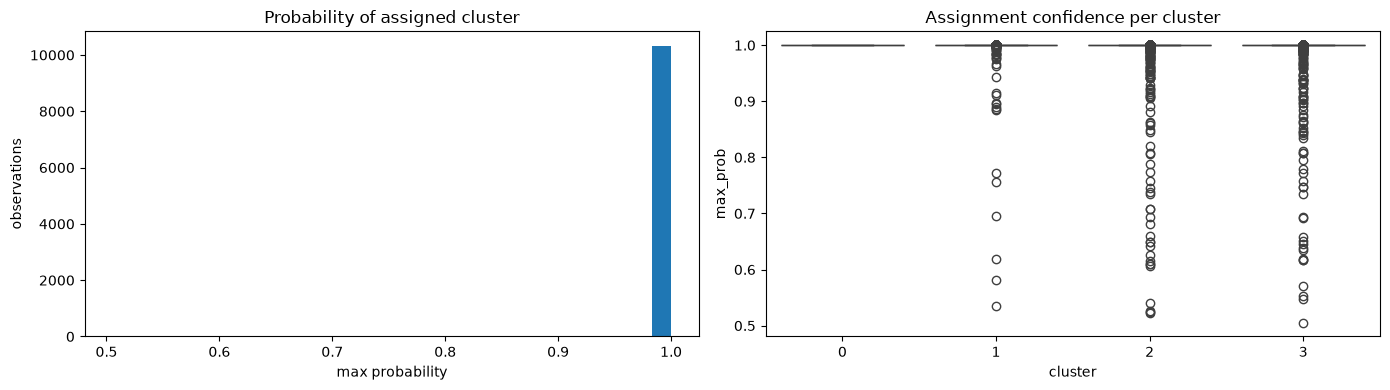

Share of observations with max probability < 0.6 (uncertain): 0.001


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(data['max_prob'], bins=30)
axes[0].set(title='Probability of assigned cluster', xlabel='max probability', ylabel='observations')
sns.boxplot(data=data, x='cluster', y='max_prob', ax=axes[1])
axes[1].set(title='Assignment confidence per cluster')
plt.tight_layout()
plt.show()

print('Share of observations with max probability < 0.6 (uncertain):',
      round((data['max_prob'] < 0.6).mean(), 3))

## Stability
Refit with different random starts and bootstrap samples; compare labels with the final fit (ARI: 1 = identical).

In [8]:
def stability(M, k, n_boot=10):
    rng = np.random.default_rng(RANDOM_STATE)
    full = GaussianMixture(n_components=k, covariance_type=COVARIANCE_TYPE, n_init=3,
                           random_state=RANDOM_STATE).fit(M).predict(M)
    scores = []
    for b in range(n_boot):
        idx = rng.choice(len(M), len(M), replace=True)
        g = GaussianMixture(n_components=k, covariance_type=COVARIANCE_TYPE, n_init=3,
                            random_state=b).fit(M[idx])
        scores.append(adjusted_rand_score(full, g.predict(M)))
    return np.mean(scores)

display(pd.Series({k: stability(X_scaled, k) for k in range(3, 7)}, name='mean ARI').round(3).to_frame())

,mean ARI
3,0.762
4,0.562
5,0.892
6,0.838


## Cluster profile
Heatmap: mean z-score per cluster (red = above average, blue = below average), clusters ordered by bad rate.

,n_obs,share_%,bad_rate_%
cluster,,,
3,5344,50.9,39.6
2,1466,14.0,53.7
1,2108,20.1,58.2
0,1581,15.1,83.7


,avg_period_income,income_cv,recent_vs_avg_income,pay_gap_cv,avg_spend_ratio,avg_spend_per_day,avg_frac_to_half,avg_first3_share,bal7_ratio_avg,bal7_ratio_change,committed_share_after_pay
cluster,,,,,,,,,,,
3,9333.33,0.24,1.00,0.17,2.10,747.31,0.03,1.10,0.03,0.00,0.20
2,1875.12,0.71,0.97,0.44,4.89,424.17,0.03,1.63,0.02,-0.01,0.05
1,4834.82,0.87,0.85,0.23,2.01,453.07,0.01,1.01,0.03,0.00,0.13
0,333.33,1.63,0.82,0.23,2.22,630.40,0.02,1.10,0.03,0.00,0.00


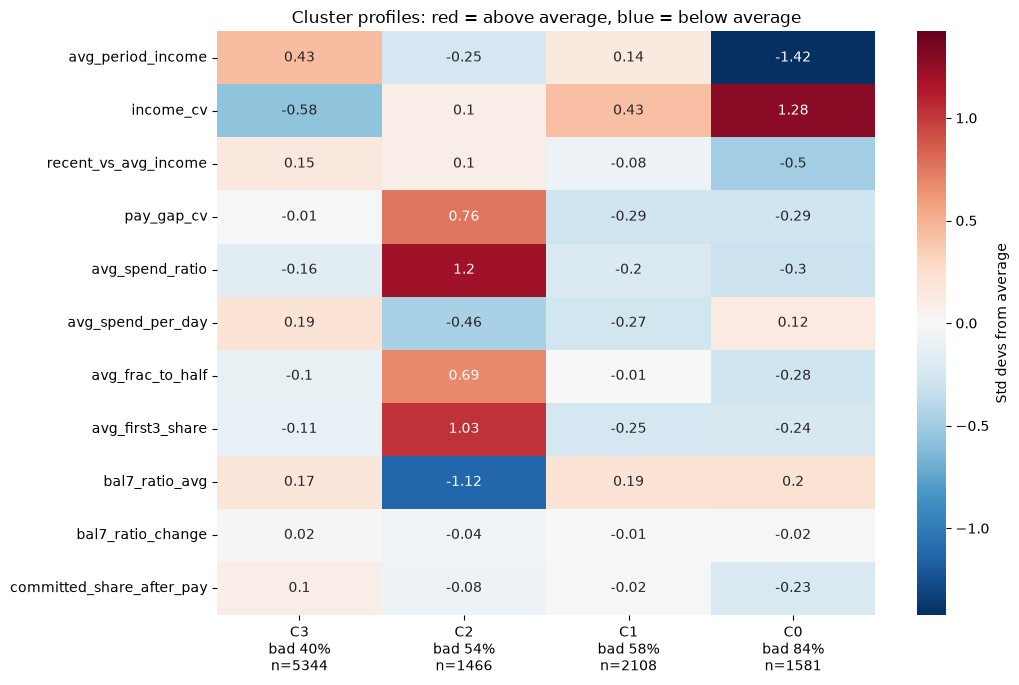

,no_income_detected,few_pay_events,no_complete_cycle,no_bal7_history
cluster,,,,
3,0.00,0.00,0.0,0.00
2,0.00,0.21,0.0,0.03
1,0.00,1.00,0.0,0.25
0,0.27,1.00,1.0,1.00


In [9]:
data['target_value'] = base['target_value'].to_numpy()

profile = data.groupby('cluster').agg(n_obs=('obs_id', 'size'), bad_rate=('target_value', 'mean'))
profile['share_%'] = (profile['n_obs'] / profile['n_obs'].sum() * 100).round(1)
profile['bad_rate_%'] = (profile['bad_rate'] * 100).round(1)
order = profile.sort_values('bad_rate').index
display(profile.loc[order, ['n_obs', 'share_%', 'bad_rate_%']])

display(data.groupby('cluster')[CLUSTER_FEATURES].median().loc[order].round(2))

z = X_scaled_df[CLUSTER_FEATURES].groupby(data['cluster'].to_numpy()).mean().T[order]
lim = min(np.abs(z.values).max(), 2)
fig, ax = plt.subplots(figsize=(1.4 * len(order) + 5, 0.45 * len(z) + 2))
sns.heatmap(z.clip(-lim, lim), annot=z.round(2), fmt='', cmap='RdBu_r', center=0, vmin=-lim, vmax=lim,
            cbar_kws={'label': 'Std devs from average'}, ax=ax)
ax.set_xticklabels([f'C{c}\nbad {profile.loc[c, "bad_rate"]:.0%}\nn={profile.loc[c, "n_obs"]}' for c in order],
                   rotation=0)
ax.set_xlabel('')
ax.set_title('Cluster profiles: red = above average, blue = below average')
plt.tight_layout()
plt.show()

# Share of each cluster with each missing-data flag (filled values sit at the median, so check this)
display(flags.groupby(data['cluster'].to_numpy()).mean().loc[order].round(2).rename_axis('cluster'))

## Bad rate (incl. observations that could not be clustered) and stability over months

In [10]:
val = base[['obs_id', 'target_value', 'm0_monthenddate', 'product_group', 'm0_start_cd_group']].merge(
    data[['obs_id', 'cluster']], on='obs_id', how='left')
val['cluster'] = val['cluster'].astype('Int64').astype(str).replace('<NA>', 'not clustered')
print(f"Overall bad rate: {val['target_value'].mean() * 100:.1f}%")
display(val.groupby('cluster')['target_value'].agg(n_obs='size', bad_rate='mean')
        .assign(bad_rate=lambda d: (d['bad_rate'] * 100).round(1)))

val['m0_month'] = pd.to_datetime(val['m0_monthenddate']).dt.to_period('M')
print('Cluster share by m0 month (%) - rows should look similar if the clusters are stable')
display(pd.crosstab(val['m0_month'], val['cluster'], normalize='index').mul(100).round(1))
print('Bad rate by m0 month (%)')
display(val.pivot_table(index='m0_month', columns='cluster', values='target_value', aggfunc='mean')
        .mul(100).round(1))

Overall bad rate: 51.9%


,n_obs,bad_rate
cluster,,
0,1581,83.7
1,2108,58.2
2,1466,53.7
3,5344,39.6


Cluster share by m0 month (%) - rows should look similar if the clusters are stable


cluster,0,1,2,3
m0_month,,,,
2025-09,16.1,18.1,13.5,52.3
2025-10,16.5,19.2,13.8,50.5
2025-11,15.9,20.5,13.5,50.1
2025-12,15.9,20.0,15.0,49.0
2026-01,12.6,19.0,14.1,54.2
2026-02,14.1,23.3,13.8,48.9


Bad rate by m0 month (%)


cluster,0,1,2,3
m0_month,,,,
2025-09,78.1,55.3,58.1,39.8
2025-10,81.4,60.2,61.3,43.8
2025-11,86.2,67.6,57.1,43.0
2025-12,85.4,64.1,55.7,41.7
2026-01,84.3,52.7,45.6,32.0
2026-02,86.7,51.7,47.7,40.0


## Static attributes per cluster
How the behavioural clusters relate to the existing static segments.

In [11]:
display(pd.crosstab(val['cluster'], val['product_group'], normalize='index').mul(100).round(1))
display(pd.crosstab(val['cluster'], val['m0_start_cd_group'], normalize='index').mul(100).round(1))

product_group,ACC,NPDM,PDM
cluster,,,
0,16.6,21.3,62.2
1,14.0,26.1,59.9
2,6.9,32.1,61.0
3,11.5,40.8,47.8


m0_start_cd_group,CD 1,CD 2,CD 3
cluster,,,
0,32.5,34.3,33.1
1,63.6,23.3,13.1
2,56.8,26.9,16.2
3,68.1,20.1,11.8


## 2D view (PCA)

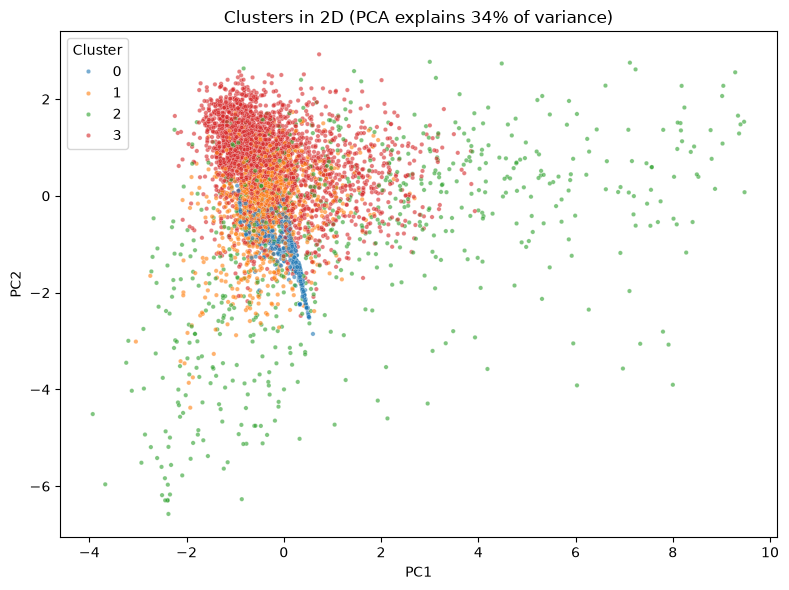

In [12]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)
idx = np.random.default_rng(RANDOM_STATE).choice(len(coords), min(5_000, len(coords)), replace=False)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=coords[idx, 0], y=coords[idx, 1], hue=data['cluster'].to_numpy()[idx],
                palette='tab10', s=10, alpha=0.6)
plt.title(f'Clusters in 2D (PCA explains {pca.explained_variance_ratio_.sum() * 100:.0f}% of variance)')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

## Compare with k-means (if `cluster_kmeans.ipynb` has been run)

In [13]:
import os
if os.path.exists('output/clusters_kmeans.parquet'):
    km_lab = pd.read_parquet('output/clusters_kmeans.parquet').rename(columns={'cluster': 'kmeans'})
    comp = data[['obs_id', 'cluster']].rename(columns={'cluster': 'gmm'}).merge(km_lab, on='obs_id')
    print('Adjusted Rand index GMM vs k-means:', round(adjusted_rand_score(comp['gmm'], comp['kmeans']), 3))
    display(pd.crosstab(comp['gmm'], comp['kmeans'], rownames=['GMM'], colnames=['k-means']))
else:
    print('Run cluster_kmeans.ipynb first to compare.')

Adjusted Rand index GMM vs k-means: 0.427


k-means,0,1,2,3
GMM,,,,
0,1558,23,0,0
1,1079,1020,7,2
2,223,371,470,402
3,433,4811,100,0


## Save labels and probabilities

In [14]:
cols = ['obs_id', 'cluster', 'max_prob'] + [f'prob_{c}' for c in range(K)]
data[cols].to_parquet('output/clusters_gmm.parquet', index=False)
print('Saved output/clusters_gmm.parquet')

Saved output/clusters_gmm.parquet
